# Traffic Collision Data Analysis

# Objective

In this case study, you will be working on California Traffic Collision Data Analysis using Apache Spark, a powerful distributed computing framework designed for big data processing. This assignment aims to provide hands-on experience in analyzing large-scale traffic collision datasets using PySpark and AWS services. You will apply data analytics techniques to clean, transform, and explore crash data, drawing meaningful insights to support traffic safety and urban planning. Beyond understanding how big data tools optimize performance on a single machine and across clusters, you will develop a structured approach to analyzing crash trends, identifying high-risk locations, and evaluating contributing factors to traffic incidents. Additionally, you will utilize AWS S3 to store the processed data efficiently after the ETL process, enabling scalable storage and easy retrieval for further analysis.


# Business Value:

Traffic collisions pose significant risks to public safety, requiring continuous monitoring and analysis to enhance road safety measures. Government agencies, city planners, and policymakers must leverage data-driven insights to improve infrastructure, optimize traffic management, and implement preventive measures.

In this assignment, you will analyze California traffic collision data to uncover patterns related to accident severity, location-based risks, and key contributing factors. With Apache Spark's ability to handle large datasets efficiently and AWS S3's scalable storage, transportation authorities can process vast amounts of crash data in real time, enabling faster and more informed decision-making.

As an analyst examining traffic safety trends, your task is to analyze historical crash data to derive actionable insights that can drive policy improvements and safety interventions. Your analysis will help identify high-risk areas, categorize accidents by severity and contributing factors, and store the processed data in an AWS S3 bucket for scalable and long-term storage.

By leveraging big data analytics and cloud-based storage, urban planners and traffic authorities can enhance road safety strategies, reduce accident rates, and improve public transportation planning.


# Dataset Overview

The dataset used in this analysis consists of California traffic collision data obtained from the Statewide Integrated Traffic Records System (SWITRS). It includes detailed records of traffic incidents across California, covering various attributes such as location, severity, involved parties, and contributing factors. The dataset has been preprocessed and transformed using PySpark to facilitate large-scale analysis. By leveraging Apache Spark, we ensure efficient data handling, enabling deeper insights into traffic patterns, accident trends, and potential safety improvements.

The dataset is a .sqlite file contains detailed information about traffic collisions across California and is structured into four primary tables:
- `collisions` table contains information about the collision, where it happened, what vehicles were involved.

- `parties` table contains information about the groups people involved in the collision including age, sex, and sobriety.

- `victims` table contains information about the injuries of specific people involved in the collision.

- `locations` table contains information about the geographical location and details of road intersections.

# Assignment Tasks

<ol>
    <li>
        <strong>Data Preparation</strong></br>
        The dataset consists of structured tables containing traffic collision data. Before conducting any analysis, it is essential to ensure that the data is properly formatted and structured for efficient processing.</br>
        Check for data consistency and ensure all columns are correctly formatted.</br>
        Apply sampling techniques if needed to extract a representative subset for analysis.</br>
        Structure and prepare the data for further processing and analysis.</br>
    </br>
    <li>
        <strong>Data Cleaning</strong></br>
            2.1 <strong>Fixing Columns:</strong> Ensure all columns are properly named and formatted.</br>
            2.2 <strong>Handling Missing Values:</strong> Decide on an approach to handle missing data (e.g., imputation or removal). Mention the approach in your report.</br>
            2.3 <strong>Handling Outliers:</strong> Identify outliers in the dataset and explain why they are considered outliers. It is not necessary to remove them for this task, but mention your approach for handling them.</br>
    </br>
    <li>
        <strong>Exploratory Data Analysis</strong></br>
        Finding Patterns and analyze the dataset and find patterns based on the following points:
                <ul>
                3.1 Classify variables into categorical and numerical types.</br>
                3.2 Analyze the distribution of collision severity.</br>
                3.3 Examine weather conditions during collisions.</br>
                3.4 Analyze the distribution of victim ages.</br>
                3.5 Study the relationship between collision severity and the number of victims.</br>
                3.6 Analyze the correlation between weather conditions and collision severity.</br>
                3.7 Visualize the impact of lighting conditions on collision severity.</br>
                3.8 Extract and analyze weekday-wise collision trends.</br>
                3.9 Assess the number of collisions occurring on different days of the week.</br>
                3.10 Study spatial distribution of collisions by county.</br>
                3.11 Generate a scatter plot to analyze collision locations geographically.</br>
                3.12 Extract and analyze collision trends over time, including yearly, monthly, and hourly trends.</br>
</ul>
</br>
<li>
<strong>ETL Querying</strong><br>
Write PySpark SQL queries for the following:</br>
<ol>
    4.1. Identify the top 5 counties with the highest number of collisions.</br>
    4.2. Identify the month with the highest number of collisions.</br>
    4.3. Determine the most common weather condition during collisions.</br>
    4.4. Calculate the percentage of collisions that resulted in fatalities.</br>
    4.5. Find the most dangerous time of day for collisions.</br>
    4.6. Identify the top 5 road surface conditions with the highest collision frequency.</br>
    4.7. Analyze lighting conditions that contribute to the highest number of collisions.</br>
</ol>
</br>
<li>
<strong>Conclusion</strong></br>
Provide final insights and recommendations based on the analysis:
    <ul>
        5.1 Recommendations to improve road safety by identifying high-risk locations and peak accident times for infrastructure improvements.</br>
        5.2 Suggestions to optimize traffic management by analyzing trends in collision severity, weather conditions, and lighting to improve road design and traffic signal timing.</br>
        5.3 Propose data-driven policy changes to enhance pedestrian and cyclist safety based on collision trends involving vulnerable road users.</br>
        5.4 Identify potential high-risk zones for proactive intervention by examining geographic collision density and historical accident data.</br>
        5.5 Assess the impact of environmental factors such as weather, road surface conditions, and lighting on accident frequency and severity.</br>
        5.6 Develop predictive models to anticipate collision hotspots and support proactive safety measures.</br>
        </ul>
        Conclude the analysis by summarizing key findings and business implications.</br>
        Explain the results of univariate, segmented univariate, and bivariate analyses in real-world traffic safety and policy terms.</br>
        Include visualizations and summarize the most important results in the report. Insights should explain why each variable is important and how they can influence traffic safety policies and urban planning.</br>
        </ul>
        </br>
    <li>
    <strong>Visualization Integration [Optional]</strong>
    <p>Enhance the project by incorporating a visualization component that connects the processed data stored in an S3 bucket to a business intelligence tool such as Tableau or Power BI. This involves setting up the connection between the S3 bucket and the chosen visualization tool, importing the processed dataset for analysis and visualization, creating interactive dashboards to explore key trends and insights and ensuring data updates are reflected dynamically in the visualization tool.<br>
</br>
</ol>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Install Required Libraries

In [2]:
# Check libraries already available in this Colab runtime
# The starter pin to pandas 2.2.2 failed under Python 3.13.
import pandas as pd
import pyspark
print("pandas:", pd.__version__, "PySpark:", pyspark.__version__)

pandas: 2.2.3 PySpark: 4.0.5


In [3]:
# Import the necessary libraries
import sqlite3
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, sum, to_date

#**1. Data Preparation** <font color = red>[5 marks]</font> <br>

The dataset consists of structured tables containing traffic collision data.

Before conducting any analysis, it is essential to ensure that the data is properly formatted and structured for efficient processing.

Check for data consistency and ensure all columns are correctly formatted.

In [4]:
# Write code to load the data and check the schema
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("TrafficCollisionAnalysis").getOrCreate()

collisions = (
    spark.read
    .option("header", "true")
    .csv("/content/drive/MyDrive/Crash Data Analysis/sample_collisions.csv")
)

collisions.printSchema()
print("Rows:", collisions.count())
collisions.select(
    "case_id", "collision_date", "county_location", "collision_severity"
).show(5, truncate=False)

root
 |-- case_id: string (nullable = true)
 |-- jurisdiction: string (nullable = true)
 |-- officer_id: string (nullable = true)
 |-- reporting_district: string (nullable = true)
 |-- chp_shift: string (nullable = true)
 |-- population: string (nullable = true)
 |-- county_city_location: string (nullable = true)
 |-- county_location: string (nullable = true)
 |-- special_condition: string (nullable = true)
 |-- beat_type: string (nullable = true)
 |-- chp_beat_type: string (nullable = true)
 |-- chp_beat_class: string (nullable = true)
 |-- beat_number: string (nullable = true)
 |-- primary_road: string (nullable = true)
 |-- secondary_road: string (nullable = true)
 |-- distance: string (nullable = true)
 |-- direction: string (nullable = true)
 |-- intersection: string (nullable = true)
 |-- weather_1: string (nullable = true)
 |-- state_highway_indicator: string (nullable = true)
 |-- caltrans_county: string (nullable = true)
 |-- caltrans_district: string (nullable = true)
 |-- st

In [5]:
data_folder = "/content/drive/MyDrive/Crash Data Analysis"

parties = spark.read.option("header", "true").csv(f"{data_folder}/sample_parties.csv")
victims = spark.read.option("header", "true").csv(f"{data_folder}/sample_victims.csv")
case_ids = spark.read.option("header", "true").csv(f"{data_folder}/sample_case_ids.csv")

print("Parties:", parties.count())
print("Victims:", victims.count())
print("Case IDs:", case_ids.count())

Parties: 1866917
Victims: 963933
Case IDs: 942433


#**2. Data Cleaning** <font color = red>[20 marks]</font> <br>


In [6]:
#Display Schema & Sample Data

print("PARTIES SCHEMA")
parties.printSchema()
parties.select(
    "case_id", "party_number", "party_type", "party_age", "at_fault"
).show(5, truncate=False)

print("VICTIMS SCHEMA")
victims.printSchema()
victims.select(
    "case_id", "party_number", "victim_role",
    "victim_age", "victim_degree_of_injury"
).show(5, truncate=False)

PARTIES SCHEMA
root
 |-- id: string (nullable = true)
 |-- case_id: string (nullable = true)
 |-- party_number: string (nullable = true)
 |-- party_type: string (nullable = true)
 |-- at_fault: string (nullable = true)
 |-- party_sex: string (nullable = true)
 |-- party_age: string (nullable = true)
 |-- party_sobriety: string (nullable = true)
 |-- direction_of_travel: string (nullable = true)
 |-- party_safety_equipment_1: string (nullable = true)
 |-- party_safety_equipment_2: string (nullable = true)
 |-- financial_responsibility: string (nullable = true)
 |-- cellphone_in_use: string (nullable = true)
 |-- cellphone_use_type: string (nullable = true)
 |-- other_associate_factor_1: string (nullable = true)
 |-- party_number_killed: string (nullable = true)
 |-- party_number_injured: string (nullable = true)
 |-- movement_preceding_collision: string (nullable = true)
 |-- vehicle_year: string (nullable = true)
 |-- vehicle_make: string (nullable = true)
 |-- statewide_vehicle_type: 

##**2.1 Missing Values** <font color = red>[10 marks]</font> <br>


In [7]:
#Check for Missing Values
from pyspark.sql import functions as F

def missing_profile(df):
    checks = [
        F.sum(F.when(
            F.col(c).isNull() |
            (F.trim(F.col(c).cast("string")) == "") |
            F.lower(F.trim(F.col(c).cast("string"))).isin("null", "none", "nan"),
            1
        ).otherwise(0)).alias(c)
        for c in df.columns
    ]
    counts = df.agg(*checks).first().asDict()
    total = df.count()
    return sorted(
        [(c, n, round(100 * n / total, 2)) for c, n in counts.items()],
        key=lambda x: x[1], reverse=True
    )

collision_missing = missing_profile(collisions)
print("Collision rows:", collisions.count())
print("Most missing collision columns (name, count, percent):")
for item in collision_missing[:25]:
    print(item)

for name, df in [("parties", parties), ("victims", victims), ("case_ids", case_ids)]:
    print("\n", name, "rows:", df.count())
    print("Most missing columns:", missing_profile(df)[:10])


Collision rows: 935791
Most missing collision columns (name, count, percent):
('side_of_highway', 682077, 72.89)
('caltrans_county', 682075, 72.89)
('location_type', 682075, 72.89)
('latitude', 669049, 71.5)
('longitude', 669049, 71.5)
('caltrans_district', 648728, 69.32)
('state_route', 648728, 69.32)
('postmile', 648728, 69.32)
('control_device', 624022, 66.68)
('pcf_violation_subsection', 601427, 64.27)
('reporting_district', 552654, 59.06)
('chp_vehicle_type_at_fault', 251662, 26.89)
('direction', 232663, 24.86)
('statewide_vehicle_type_at_fault', 186119, 19.89)
('beat_number', 80780, 8.63)
('pcf_violation', 64175, 6.86)
('special_condition', 51730, 5.53)
('pcf_violation_category', 15424, 1.65)
('intersection', 9484, 1.01)
('road_surface', 8141, 0.87)
('collision_time', 8084, 0.86)
('road_condition_1', 7903, 0.84)
('type_of_collision', 7655, 0.82)
('tow_away', 6153, 0.66)
('primary_collision_factor', 5660, 0.6)

 parties rows: 1866917
Most missing columns: [('chp_vehicle_type_towed

In [8]:
#Drop Sparse Columns
# The observed maximum missingness is 72.89%, below the 95% threshold.
# Keep latitude and longitude for the required geographic analysis.
sparse_columns = [c for c, n, pct in collision_missing if pct >= 95]
collisions_work = collisions.drop(*sparse_columns) if sparse_columns else collisions
parties_work = parties
victims_work = victims
print("Columns dropped:", sparse_columns)
print("Collision columns retained:", len(collisions_work.columns))

Columns dropped: []
Collision columns retained: 65


In [9]:
#Convert Data Types
# Standardise blank and placeholder strings while retaining case_id as text.
def normalise_text(df):
    return df.select(*[
        F.when(
            F.col(c).isNull() | (F.trim(F.col(c)) == "") |
            F.lower(F.trim(F.col(c))).isin("null", "none", "nan"),
            None
        ).otherwise(F.trim(F.col(c))).alias(c)
        for c in df.columns
    ])

collisions_typed = normalise_text(collisions_work)
parties_typed = normalise_text(parties_work)
victims_typed = normalise_text(victims_work)

count_columns = [
    "killed_victims", "injured_victims", "party_count",
    "severe_injury_count", "other_visible_injury_count",
    "complaint_of_pain_injury_count", "pedestrian_killed_count",
    "pedestrian_injured_count", "bicyclist_killed_count",
    "bicyclist_injured_count", "motorcyclist_killed_count",
    "motorcyclist_injured_count"
]
for c in count_columns:
    value = F.expr(f"try_cast(`{c}` as double)")
    collisions_typed = collisions_typed.withColumn(
        c, F.when((value >= 0) & (value == F.floor(value)), value.cast("long"))
    )
for c in ["latitude", "longitude"]:
    collisions_typed = collisions_typed.withColumn(c, F.expr(f"try_cast(`{c}` as double)"))
for c in ["collision_date", "process_date"]:
    collisions_typed = collisions_typed.withColumn(
        c, F.try_to_timestamp(F.col(c), F.lit("yyyy-MM-dd")).cast("date")
    )
for df_name, age_column in [("parties_typed", "party_age"), ("victims_typed", "victim_age")]:
    df = globals()[df_name]
    value = F.expr(f"try_cast(`{age_column}` as double)")
    globals()[df_name] = df.withColumn(
        age_column, F.when(
            (value >= 0) & (value <= 120) & (value == F.floor(value)),
            value.cast("integer")
        )
    )

print("Converted collision counts, coordinates and dates; party and victim ages.")
collisions_typed.select("case_id", "collision_date", "injured_victims", "latitude").show(3, truncate=False)
parties_typed.select("party_age").show(3)
victims_typed.select("victim_age").show(3)

Converted collision counts, coordinates and dates; party and victim ages.
+----------+--------------+---------------+--------+
|case_id   |collision_date|injured_victims|latitude|
+----------+--------------+---------------+--------+
|8000993.0 |2016-03-20    |0              |NULL    |
|4232117.0 |2009-04-13    |1              |NULL    |
|91389627.0|2021-01-09    |1              |39.12512|
+----------+--------------+---------------+--------+
only showing top 3 rows
+---------+
|party_age|
+---------+
|       28|
|       53|
|       22|
+---------+
only showing top 3 rows
+----------+
|victim_age|
+----------+
|        62|
|        25|
|        31|
+----------+
only showing top 3 rows


In [10]:
#Handle Missing Values
# Use an explicit Unknown category; never turn an unknown count into zero.
collision_categories = [
    "collision_severity", "weather_1", "lighting",
    "road_surface", "county_location"
]
collisions_filled = collisions_typed.fillna(
    "Unknown", subset=collision_categories
)
parties_filled = parties_typed.fillna(
    "Unknown", subset=["party_type", "party_sex"]
)
victims_filled = victims_typed.fillna(
    "Unknown", subset=["victim_role", "victim_sex", "victim_degree_of_injury"]
)
print("Missing categorical values labelled Unknown.")
print("Missing dates, coordinates, ages and injury counts remain null.")
print("No records removed for missingness at this stage.")
collisions_filled.groupBy("collision_severity").count().orderBy(F.desc("count")).show(10, truncate=False)

Missing categorical values labelled Unknown.
Missing dates, coordinates, ages and injury counts remain null.
No records removed for missingness at this stage.
+--------------------+------+
|collision_severity  |count |
+--------------------+------+
|property damage only|570480|
|pain                |226492|
|other injury        |116681|
|severe injury       |22138 |
+--------------------+------+



##**2.2 Fixing Columns** <font color = red>[5 marks]</font> <br>


In [11]:
#Remove Duplicates
# Remove only identical records. Distinct records sharing a case_id require review.
collisions_dedup = collisions_filled.dropDuplicates()
parties_dedup = parties_filled.dropDuplicates()
victims_dedup = victims_filled.dropDuplicates()
for name, source, cleaned in [
    ("collisions", collisions_filled, collisions_dedup),
    ("parties", parties_filled, parties_dedup),
    ("victims", victims_filled, victims_dedup),
]:
    before, after = source.count(), cleaned.count()
    print(name, "rows before:", before, "after:", after, "exact duplicates removed:", before - after)

case_id_conflicts = (collisions_dedup.groupBy("case_id")
    .count().filter(F.col("count") > 1))
print("Collision case IDs with multiple records:", case_id_conflicts.count())
case_id_conflicts.orderBy(F.desc("count")).show(10, truncate=False)

collisions rows before: 935791 after: 935791 exact duplicates removed: 0
parties rows before: 1866917 after: 1866917 exact duplicates removed: 0
victims rows before: 963933 after: 963933 exact duplicates removed: 0
Collision case IDs with multiple records: 27
+---------------------+-----+
|case_id              |count|
+---------------------+-----+
|9.345010123145015e+18|2    |
|9.550010803172016e+18|2    |
|9.550010118180014e+18|2    |
|9.675010511163015e+18|2    |
|9.530011024190013e+18|2    |
|9.535010610174517e+18|2    |
|9.345010328053017e+18|2    |
|9.675010627154016e+18|2    |
|9.245010829075511e+18|2    |
|9.590010423184517e+18|2    |
+---------------------+-----+
only showing top 10 rows


In [12]:
#Detect Outliers using IQR
# Exact duplicate checks removed zero rows; use the filled frames for this scan.
outlier_checks = [
    ("parties", parties_filled, "party_age"),
    ("victims", victims_filled, "victim_age"),
    ("collisions", collisions_filled, "injured_victims"),
    ("collisions", collisions_filled, "party_count"),
]
outlier_results = []
for table_name, df, column in outlier_checks:
    q1, q3 = df.approxQuantile(column, [0.25, 0.75], 0.01)
    iqr = q3 - q1
    if iqr == 0:
        print(table_name, column, "Q1=Q3=", q1,
              "-- IQR is uninformative when values are highly concentrated")
        outlier_results.append((table_name, column, q1, q3, None))
        continue
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = df.filter(
        F.col(column).isNotNull() &
        ((F.col(column) < lower) | (F.col(column) > upper))
    ).count()
    print(table_name, column, "Q1:", q1, "Q3:", q3,
          "bounds:", (lower, upper), "flagged:", flagged)
    outlier_results.append((table_name, column, lower, upper, flagged))

parties party_age Q1: 25.0 Q3: 50.0 bounds: (-12.5, 87.5) flagged: 4548
victims victim_age Q1: 18.0 Q3: 45.0 bounds: (-22.5, 85.5) flagged: 4568
collisions injured_victims Q1: 0.0 Q3: 1.0 bounds: (-1.5, 2.5) flagged: 33313
collisions party_count Q1=Q3= 2.0 -- IQR is uninformative when values are highly concentrated


##**2.3 Outlier Analysis** <font color = red>[5 marks]</font> <br>


In [13]:
# Remove Outliers: retain plausible IQR-flagged events
# Invalid ages (<0 or >120) were set to null during type conversion.
from pyspark import StorageLevel
if "collisions_clean" in globals():
    collisions_clean.unpersist()
collisions_clean = (collisions_dedup
    .withColumn("distance", F.expr("try_cast(distance as double)"))
    .withColumn("postmile", F.expr("try_cast(postmile as double)"))
    .persist(StorageLevel.MEMORY_AND_DISK))
parties_clean = parties_dedup.persist(StorageLevel.MEMORY_AND_DISK)
victims_clean = victims_dedup.persist(StorageLevel.MEMORY_AND_DISK)
print("IQR-flagged values retained; no statistical outlier rows removed.")
print("Distance and postmile converted to numeric; population ranges remain categorical.")
print("Final row counts:", collisions_clean.count(), parties_clean.count(), victims_clean.count())

IQR-flagged values retained; no statistical outlier rows removed.
Distance and postmile converted to numeric; population ranges remain categorical.
Final row counts: 935791 1866917 963933


#**3. Exploratory Data Analysis** <font color = red>[65 marks]</font> <br>


##**3.1.1. Data Preparation** <font color = red>[5 marks]</font> <br>

Q: Classify variables into categorical and numerical.

In [14]:
# Encode Categorical Variables
from pyspark.sql.types import StringType, NumericType, DateType
from pyspark.ml.feature import StringIndexer

identifier_columns = ["case_id"]
cat_columns = [f.name for f in collisions_clean.schema.fields
               if isinstance(f.dataType, StringType)
               and f.name not in identifier_columns + ["collision_time"]]
num_columns = [f.name for f in collisions_clean.schema.fields
               if isinstance(f.dataType, NumericType)]
date_columns = [f.name for f in collisions_clean.schema.fields
                if isinstance(f.dataType, DateType)]
print("Identifiers:", identifier_columns)
print("Categorical variables:", cat_columns)
print("Numerical variables:", num_columns)
print("Date variables:", date_columns, "; time text: collision_time")

# String indices are for later modelling; retain the original labels for EDA.
index_inputs = ["collision_severity", "weather_1", "lighting"]
index_outputs = [c + "_index" for c in index_inputs]
indexer = StringIndexer(inputCols=index_inputs,
                        outputCols=index_outputs, handleInvalid="keep")
indexed_collisions = indexer.fit(collisions_clean).transform(collisions_clean)
indexed_collisions.select(*index_inputs, *index_outputs).show(5, truncate=False)

Identifiers: ['case_id']
Categorical variables: ['jurisdiction', 'officer_id', 'reporting_district', 'chp_shift', 'population', 'county_city_location', 'county_location', 'special_condition', 'beat_type', 'chp_beat_type', 'chp_beat_class', 'beat_number', 'primary_road', 'secondary_road', 'direction', 'intersection', 'weather_1', 'state_highway_indicator', 'caltrans_county', 'caltrans_district', 'state_route', 'location_type', 'side_of_highway', 'tow_away', 'collision_severity', 'primary_collision_factor', 'pcf_violation_category', 'pcf_violation', 'pcf_violation_subsection', 'hit_and_run', 'type_of_collision', 'motor_vehicle_involved_with', 'pedestrian_action', 'road_surface', 'road_condition_1', 'lighting', 'control_device', 'chp_road_type', 'pedestrian_collision', 'bicycle_collision', 'motorcycle_collision', 'truck_collision', 'not_private_property', 'statewide_vehicle_type_at_fault', 'chp_vehicle_type_at_fault']
Numerical variables: ['distance', 'postmile', 'killed_victims', 'injure

In [15]:
# Reordering & Renaming Columns
analysis_collisions = (indexed_collisions
    .withColumnRenamed("weather_1", "weather_condition")
    .withColumnRenamed("county_location", "county"))
lead_columns = ["case_id", "collision_date", "collision_time", "county",
                "collision_severity", "weather_condition", "lighting",
                "road_surface", "injured_victims", "killed_victims",
                "party_count", "latitude", "longitude"]
analysis_collisions = analysis_collisions.select(
    *lead_columns, *[c for c in analysis_collisions.columns if c not in lead_columns]
)
print("Clear names and leading analysis columns:", analysis_collisions.columns[:13])

Clear names and leading analysis columns: ['case_id', 'collision_date', 'collision_time', 'county', 'collision_severity', 'weather_condition', 'lighting', 'road_surface', 'injured_victims', 'killed_victims', 'party_count', 'latitude', 'longitude']


In [16]:
# Final cleaned data
analysis_parties = parties_clean
analysis_victims = victims_clean
print("Analysis table rows:")
print("collisions:", analysis_collisions.count())
print("parties:", analysis_parties.count())
print("victims:", analysis_victims.count())
print("Use collision-level injury counts for collision-level analyses.")
print("Victim ages are analysed within the separate victim sample.")

Analysis table rows:
collisions: 935791
parties: 1866917
victims: 963933
Use collision-level injury counts for collision-level analyses.
Victim ages are analysed within the separate victim sample.


Loading the Final Cleaned Dataset into S3 Bucket

In [46]:
# Upload processed Parquet data after adding AWS keys to Colab Secrets.
# The secret values are never saved in this notebook.
UPLOAD_TO_S3 = True
S3_BUCKET = "nachiket-crash-analysis-2004-2707"
S3_REGION = "ap-southeast-2"
S3_PREFIX = "crash_etl"

if UPLOAD_TO_S3:
    # Auto-install boto3 in Colab runtime if missing
    try:
        import boto3
    except ModuleNotFoundError:
        import sys
        from IPython import get_ipython
        print("Installing missing library 'boto3'...")
        get_ipython().system(f"{sys.executable} -m pip install boto3")
        import boto3

    from pathlib import Path
    from google.colab import userdata

    access_key = userdata.get("AWS_ACCESS_KEY_ID")
    secret_key = userdata.get("AWS_SECRET_ACCESS_KEY")
    s3 = boto3.client(
        "s3",
        region_name=S3_REGION,
        aws_access_key_id=access_key,
        aws_secret_access_key=secret_key,
    )
    export_root = Path("/content/crash_etl_parquet")
    uploaded_keys = []
    for name, df in [
        ("collisions", analysis_collisions),
        ("parties", analysis_parties),
        ("victims", analysis_victims),
    ]:
        table_dir = export_root / name
        df.write.mode("overwrite").parquet(str(table_dir))
        for part in table_dir.rglob("*.parquet"):
            key = f"{S3_PREFIX}/{name}/{part.name}"
            s3.upload_file(str(part), S3_BUCKET, key)
            uploaded_keys.append(key)
        print("Uploaded", name, "to", f"s3://{S3_BUCKET}/{S3_PREFIX}/{name}/")
    found_keys = set()
    for page in s3.get_paginator("list_objects_v2").paginate(Bucket=S3_BUCKET, Prefix=f"{S3_PREFIX}/"):
        found_keys.update(obj["Key"] for obj in page.get("Contents", []))
    missing_keys = set(uploaded_keys) - found_keys
    if missing_keys:
        raise RuntimeError(f"Uploaded files not visible in S3: {len(missing_keys)}")
    print("Verified", len(uploaded_keys), "Parquet files in S3")
else:
    print("S3 upload pending: add AWS keys to Colab Secrets, then set UPLOAD_TO_S3=True.")

Installing missing library 'boto3'...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.2/16.2 MB 73.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [boto3]
Uploaded collisions to s3://nachiket-crash-analysis-2004-2707/crash_etl/collisions/
Uploaded parties to s3://nachiket-crash-analysis-2004-2707/crash_etl/parties/
Uploaded victims to s3://nachiket-crash-analysis-2004-2707/crash_etl/victims/
Verified 600 Parquet files in S3


##**3.1.2. Analyze the distribution of collision severity.** <font color = red>[5 marks]</font> <br>

Q: Analyze the distribution of collision severity.

  collision_severity  count  percentage
property damage only 570480       60.96
                pain 226492       24.20
        other injury 116681       12.47
       severe injury  22138        2.37


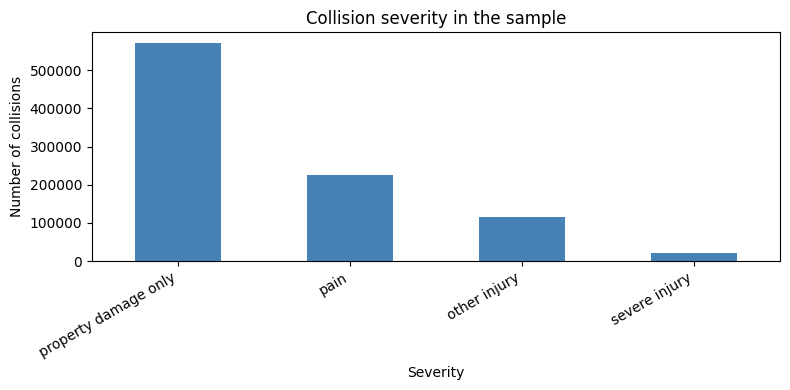

In [18]:
# Univariate Analysis: collision severity distribution
import matplotlib.pyplot as plt
severity_counts = (analysis_collisions.groupBy("collision_severity")
                   .count().orderBy(F.desc("count")).toPandas())
severity_counts["percentage"] = (100 * severity_counts["count"]
                                 / severity_counts["count"].sum()).round(2)
print(severity_counts.to_string(index=False))
ax = severity_counts.plot.bar(x="collision_severity", y="count", legend=False,
                              figsize=(8, 4), color="steelblue")
ax.set(title="Collision severity in the sample", xlabel="Severity",
       ylabel="Number of collisions")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

##**3.1.3. Weather conditions during collisions.** <font color = red>[5 marks]</font> <br>

Q: Examine weather conditions during collisions.

weather_condition  count  percentage
            clear 769927       82.28
           cloudy 122155       13.05
          raining  32341        3.46
          Unknown   4626        0.49
              fog   3901        0.42
          snowing   1370        0.15
            other   1081        0.12
             wind    390        0.04


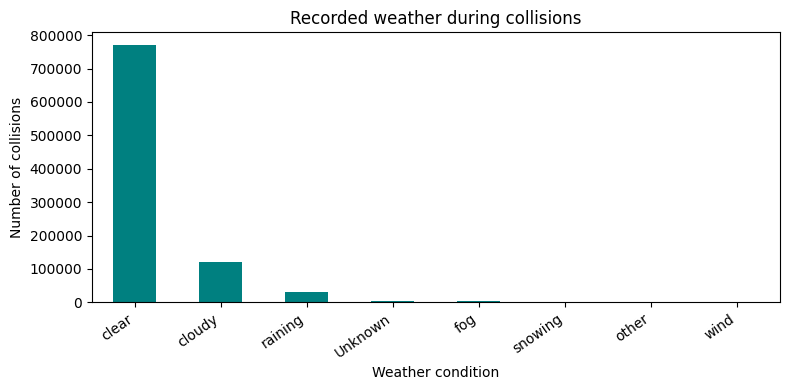

In [19]:
# Weather Conditions During Collisions
weather_counts = (analysis_collisions.groupBy("weather_condition")
                  .count().orderBy(F.desc("count")).toPandas())
weather_counts["percentage"] = (100 * weather_counts["count"]
                                / weather_counts["count"].sum()).round(2)
print(weather_counts.to_string(index=False))
ax = weather_counts.head(10).plot.bar(
    x="weather_condition", y="count", legend=False, figsize=(8, 4),
    color="teal")
ax.set(title="Recorded weather during collisions",
       xlabel="Weather condition", ylabel="Number of collisions")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

##**3.1.4. Victime Age Distribution.** <font color = red>[5 marks]</font> <br>

Q: Analyze the distribution of victim ages.

Victims with a valid age: 931758 ; missing or invalid: 32175
Most frequent ages:
 victim_age  count
         18  30644
         19  30095
         20  27749
         21  27072
         17  25771
         22  24600
         23  23289
         24  21827
         16  20825
         25  20513


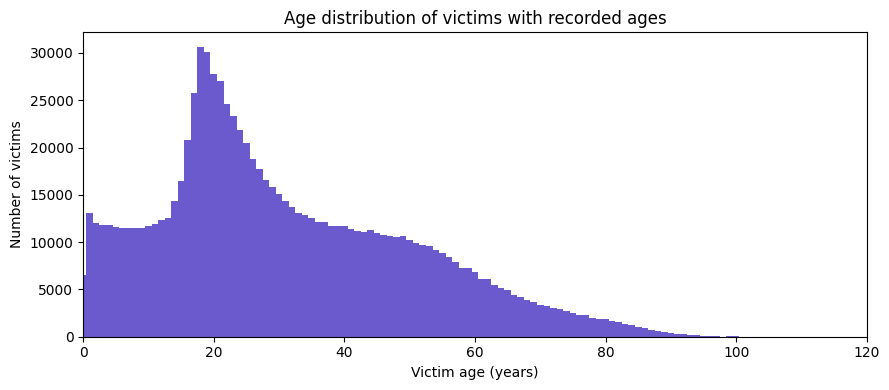

In [20]:
# Distribution of Victim Ages
age_counts = (analysis_victims.filter(F.col("victim_age").isNotNull())
              .groupBy("victim_age").count().orderBy("victim_age").toPandas())
known_age = int(age_counts["count"].sum())
missing_age = analysis_victims.count() - known_age
print("Victims with a valid age:", known_age, "; missing or invalid:", missing_age)
print("Most frequent ages:")
print(age_counts.nlargest(10, "count").to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(age_counts["victim_age"], age_counts["count"], width=1, color="slateblue")
ax.set(title="Age distribution of victims with recorded ages",
       xlabel="Victim age (years)", ylabel="Number of victims", xlim=(0, 120))
plt.tight_layout()
plt.show()

##**3.1.5. Collision Severity vs Number of Victims.** <font color = red>[5 marks]</font> <br>

Q: Study the relationship between collision severity and the number of victims.

  collision_severity  collisions  mean_victims  median_victims
property damage only      570200      0.000000               0
                pain      226435      1.369130               1
        other injury      116652      1.513202               1
       severe injury       22133      1.620702               1


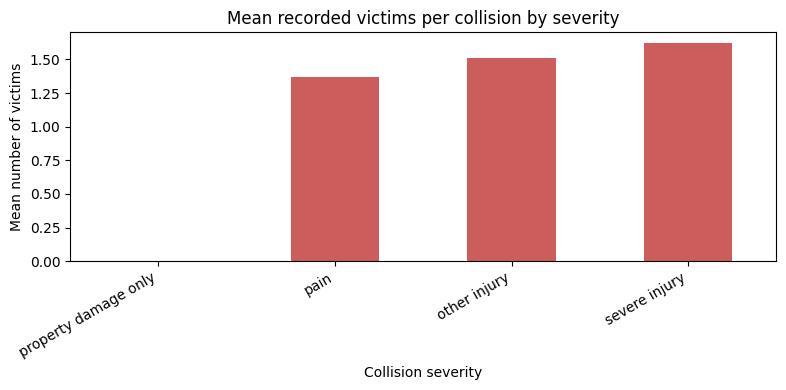

In [21]:
# Bivariate Analysis: Collision Severity vs. Number of Victims
# Use counts recorded on each collision, without joining independent samples.
severity_victims = (analysis_collisions
    .filter(F.col("injured_victims").isNotNull() &
            F.col("killed_victims").isNotNull() &
            (F.col("collision_severity") != "Unknown"))
    .withColumn("victim_count", F.col("injured_victims") + F.col("killed_victims"))
    .groupBy("collision_severity")
    .agg(F.count("*").alias("collisions"),
         F.avg("victim_count").alias("mean_victims"),
         F.expr("percentile_approx(victim_count, 0.5)").alias("median_victims"))
    .orderBy(F.desc("collisions")).toPandas())
print(severity_victims.to_string(index=False))
ax = severity_victims.plot.bar(
    x="collision_severity", y="mean_victims", legend=False,
    figsize=(8, 4), color="indianred")
ax.set(title="Mean recorded victims per collision by severity",
       xlabel="Collision severity", ylabel="Mean number of victims")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

##**3.1.6. Weather Conditions vs Collision Severity.** <font color = red>[5 marks]</font> <br>

Q: Analyze the correlation between weather conditions and collision severity.

Collision counts by weather:
weather_condition
clear      769927
cloudy     122155
raining     32341
fog          3901
snowing      1370
other        1081
wind          390
Percentage of severe-injury collisions within each weather group:
weather_condition
clear      2.42
cloudy     2.11
raining    1.92
fog        3.59
snowing    1.53
other      2.22
wind       3.59


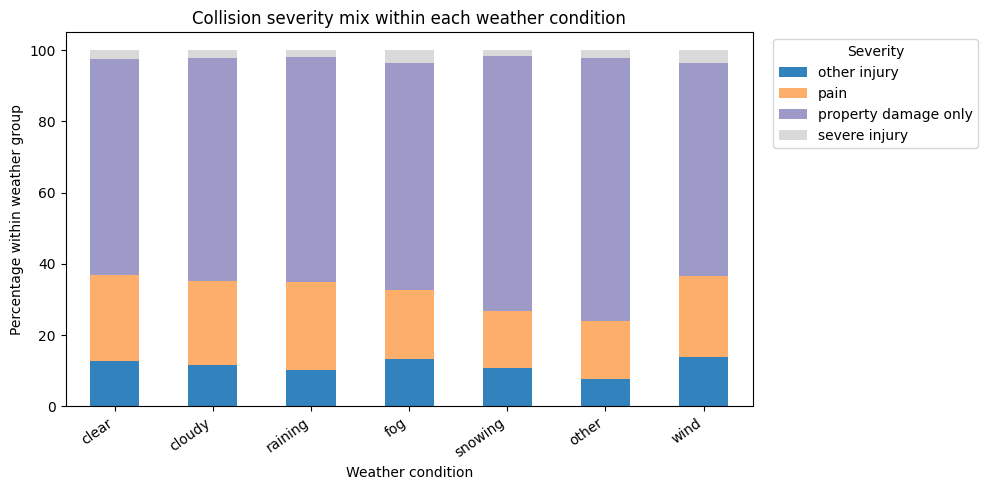

In [22]:
# Weather vs. Collision Severity
# These are categorical variables: compare within-weather percentages.
weather_severity_counts = (analysis_collisions
    .filter((F.col("weather_condition") != "Unknown") &
            (F.col("collision_severity") != "Unknown"))
    .groupBy("weather_condition", "collision_severity")
    .count().toPandas())
weather_severity_table = weather_severity_counts.pivot(
    index="weather_condition", columns="collision_severity", values="count"
).fillna(0)
weather_severity_pct = weather_severity_table.div(
    weather_severity_table.sum(axis=1), axis=0
).mul(100)
weather_severity_pct = weather_severity_pct.loc[
    weather_severity_table.sum(axis=1).sort_values(ascending=False).index
]
print("Collision counts by weather:")
print(weather_severity_table.sum(axis=1).sort_values(ascending=False).to_string())
print("Percentage of severe-injury collisions within each weather group:")
print(weather_severity_pct.get("severe injury", pd.Series(dtype=float)).round(2).to_string())
ax = weather_severity_pct.plot.bar(stacked=True, figsize=(10, 5), colormap="tab20c")
ax.set(title="Collision severity mix within each weather condition",
       xlabel="Weather condition", ylabel="Percentage within weather group")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Severity", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

##**3.1.7. Lighting conditions vs Collision Severity.** <font color = red>[5 marks]</font> <br>

Q:Visualize the impact of lighting conditions on collision severity.

Collision counts by lighting:
lighting
daylight                                   625574
dark with street lights                    195867
dark with no street lights                  74634
dusk or dawn                                32647
dark with street lights not functioning      1768
Severe-injury percentage within each lighting group:
lighting
daylight                                   1.92
dark with street lights                    2.97
dark with no street lights                 4.35
dusk or dawn                               2.74
dark with street lights not functioning    3.45


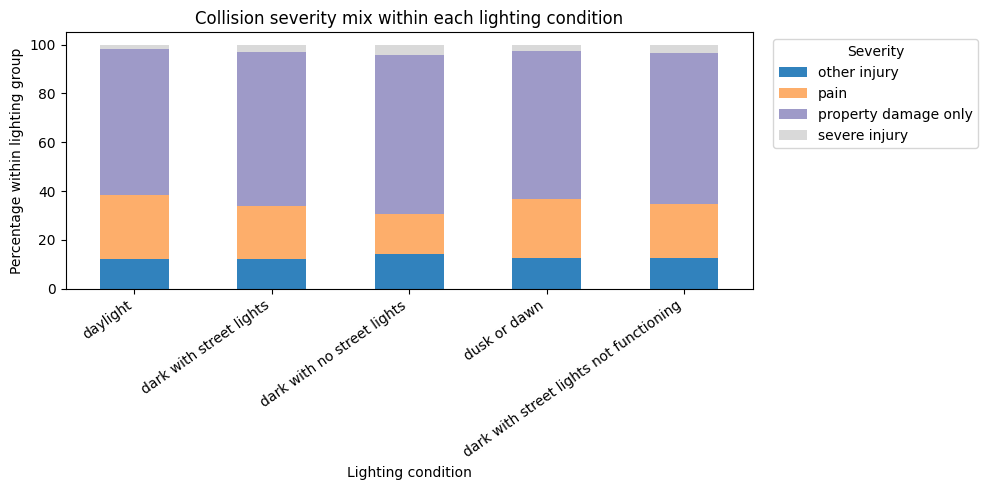

In [23]:
# Lighting Conditions vs. Collision Severity
lighting_severity_counts = (analysis_collisions
    .filter((F.col("lighting") != "Unknown") &
            (F.col("collision_severity") != "Unknown"))
    .groupBy("lighting", "collision_severity").count().toPandas())
lighting_severity_table = lighting_severity_counts.pivot(
    index="lighting", columns="collision_severity", values="count"
).fillna(0)
lighting_severity_pct = lighting_severity_table.div(
    lighting_severity_table.sum(axis=1), axis=0
).mul(100)
lighting_severity_pct = lighting_severity_pct.loc[
    lighting_severity_table.sum(axis=1).sort_values(ascending=False).index
]
print("Collision counts by lighting:")
print(lighting_severity_table.sum(axis=1).sort_values(ascending=False).to_string())
print("Severe-injury percentage within each lighting group:")
print(lighting_severity_pct.get("severe injury", pd.Series(dtype=float)).round(2).to_string())
ax = lighting_severity_pct.plot.bar(stacked=True, figsize=(10, 5), colormap="tab20c")
ax.set(title="Collision severity mix within each lighting condition",
       xlabel="Lighting condition", ylabel="Percentage within lighting group")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Severity", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

##**3.1.8. Weekday-Wise Collision Trends.** <font color = red>[7 marks]</font> <br>

Q: Extract and analyze weekday-wise collision trends.

            count
weekday          
Monday     131332
Tuesday    136972
Wednesday  137294
Thursday   138713
Friday     154544
Saturday   127855
Sunday     109081


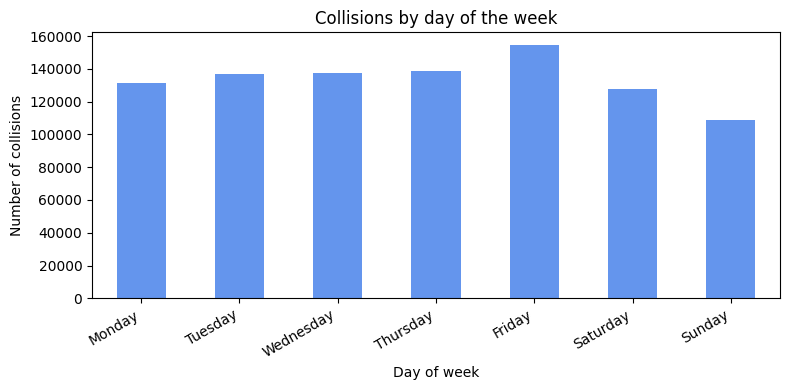

In [24]:
# Extract the weekday and analyse collision counts
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday",
                 "Friday", "Saturday", "Sunday"]
weekday_counts = (analysis_collisions
    .filter(F.col("collision_date").isNotNull())
    .withColumn("weekday", F.date_format("collision_date", "EEEE"))
    .groupBy("weekday").count().toPandas()
    .set_index("weekday").reindex(weekday_order).fillna(0))
weekday_counts["count"] = weekday_counts["count"].astype(int)
print(weekday_counts.to_string())
ax = weekday_counts.plot.bar(y="count", legend=False, figsize=(8, 4),
                             color="cornflowerblue")
ax.set(title="Collisions by day of the week", xlabel="Day of week",
       ylabel="Number of collisions")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

##**3.1.9. Spatial Distribution of Collisions.** <font color = red>[7 marks]</font> <br>

Q: Study spatial distribution of collisions by county.

Top 15 counties by recorded collisions:
        county  count  percentage
   los angeles 284100       30.36
        orange  72042        7.70
san bernardino  56737        6.06
     san diego  53105        5.67
     riverside  48686        5.20
       alameda  46525        4.97
    sacramento  40503        4.33
   santa clara  34116        3.65
  contra costa  21460        2.29
   san joaquin  20621        2.20
       ventura  20260        2.17
          kern  19348        2.07
        fresno  17438        1.86
     san mateo  16703        1.78
    stanislaus  14295        1.53


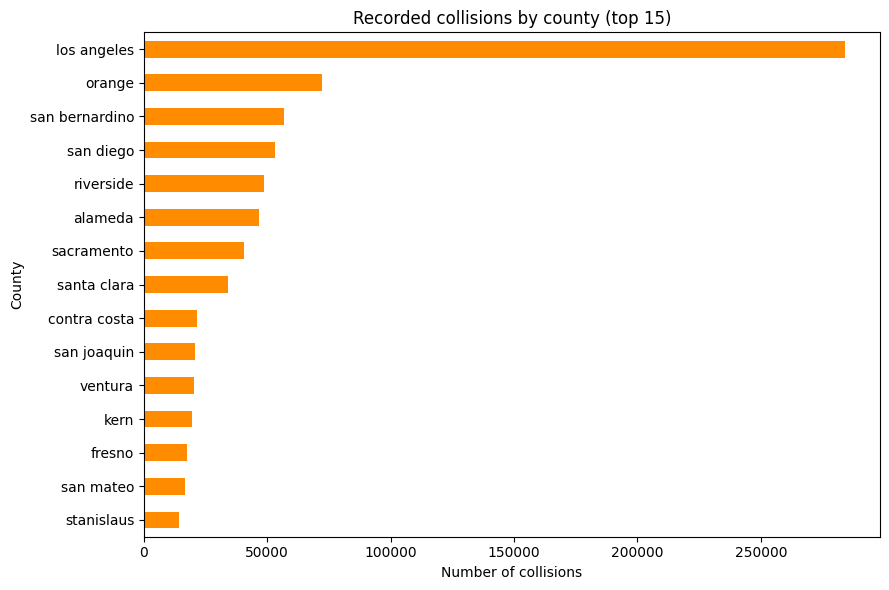

Counts describe this sample, not collision risk per resident or mile travelled.


In [25]:
# Spatial Analysis: collision counts by county
county_counts = (analysis_collisions
    .filter(F.col("county") != "Unknown")
    .groupBy("county").count().orderBy(F.desc("count")).toPandas())
county_counts["percentage"] = (100 * county_counts["count"]
                               / county_counts["count"].sum()).round(2)
print("Top 15 counties by recorded collisions:")
print(county_counts.head(15).to_string(index=False))
ax = county_counts.head(15).iloc[::-1].plot.barh(
    x="county", y="count", legend=False, figsize=(9, 6), color="darkorange")
ax.set(title="Recorded collisions by county (top 15)",
       xlabel="Number of collisions", ylabel="County")
plt.tight_layout()
plt.show()
print("Counts describe this sample, not collision risk per resident or mile travelled.")

##**3.1.10. Collision Analysis by Geography.** <font color = red>[6 marks]</font> <br>

Q: Generate a scatter plot to analyze collision locations geographically.

Collisions with valid coordinates: 266742 of 935791
Points plotted: 26868


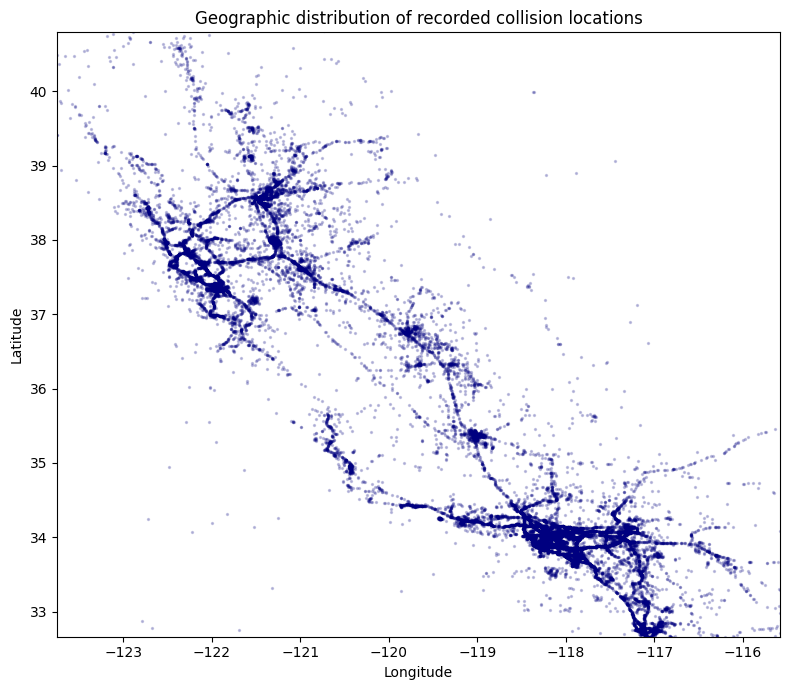

Axis limits exclude extreme coordinates from view; counts retain all valid records.


In [26]:
# Scatter Plot of Collision Locations
# Coordinates were converted to doubles during cleaning.
valid_locations = analysis_collisions.filter(
    F.col("latitude").between(-90, 90) &
    F.col("longitude").between(-180, 180)
)
location_count = valid_locations.count()
print("Collisions with valid coordinates:", location_count,
      "of", analysis_collisions.count())
# Sample 10% for a readable plot and repeatable result.
location_sample = (valid_locations.sample(False, 0.10, seed=42)
                   .select("longitude", "latitude").toPandas())
print("Points plotted:", len(location_sample))
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(location_sample["longitude"], location_sample["latitude"],
           s=2, alpha=0.2, color="navy", rasterized=True)
ax.set(title="Geographic distribution of recorded collision locations",
       xlabel="Longitude", ylabel="Latitude")
ax.set_xlim(*location_sample["longitude"].quantile([0.005, 0.995]))
ax.set_ylim(*location_sample["latitude"].quantile([0.005, 0.995]))
plt.tight_layout()
plt.show()
print("Axis limits exclude extreme coordinates from view; counts retain all valid records.")

##**3.1.11. Collision Trends Over Time.** <font color = red>[10 marks]</font> <br>

Extract and analyzing collision trends over time.

In [27]:
# Extract year, month, weekday and hour from recorded collision fields
time_head = F.split(F.col("collision_time"), ":").getItem(0)
hour_raw = F.when(time_head.rlike(r"^[0-9]{1,2}$"), time_head.cast("int"))
analysis_time = (analysis_collisions
    .withColumn("collision_year", F.year("collision_date"))
    .withColumn("collision_month", F.month("collision_date"))
    .withColumn("collision_weekday", F.date_format("collision_date", "EEEE"))
    .withColumn("collision_hour",
                F.when(hour_raw.between(0, 23), hour_raw)))
analysis_time.select("collision_date", "collision_time",
                     "collision_year", "collision_month",
                     "collision_weekday", "collision_hour").show(8, truncate=False)
analysis_time.agg(
    F.count("*").alias("total_rows"),
    F.count("collision_date").alias("valid_dates"),
    F.count("collision_hour").alias("valid_hours")
).show()

+--------------+--------------+--------------+---------------+-----------------+--------------+
|collision_date|collision_time|collision_year|collision_month|collision_weekday|collision_hour|
+--------------+--------------+--------------+---------------+-----------------+--------------+
|2012-09-01    |10:43:00      |2012          |9              |Saturday         |10            |
|2017-02-09    |14:59:00      |2017          |2              |Thursday         |14            |
|2003-01-19    |20:50:00      |2003          |1              |Sunday           |20            |
|2006-11-10    |17:05:00      |2006          |11             |Friday           |17            |
|2005-08-16    |12:35:00      |2005          |8              |Tuesday          |12            |
|2013-07-01    |06:57:00      |2013          |7              |Monday           |6             |
|2017-02-01    |00:41:00      |2017          |2              |Wednesday        |0             |
|2018-05-15    |03:39:00      |2018     

Q: Analyze yearly, monthly and hourly trends in collisions.

 collision_year  count
           2001  51921
           2002  53708
           2003  53605
           2004  53704
           2005  53074
           2006  49642
           2007  49560
           2008  44882
           2009  42421
           2010  41320
           2011  40092
           2012  39689
           2013  38234
           2014  39702
           2015  43367
           2016  49167
           2017  48408
           2018  47951
           2019  46126
           2020  36020
           2021  13198


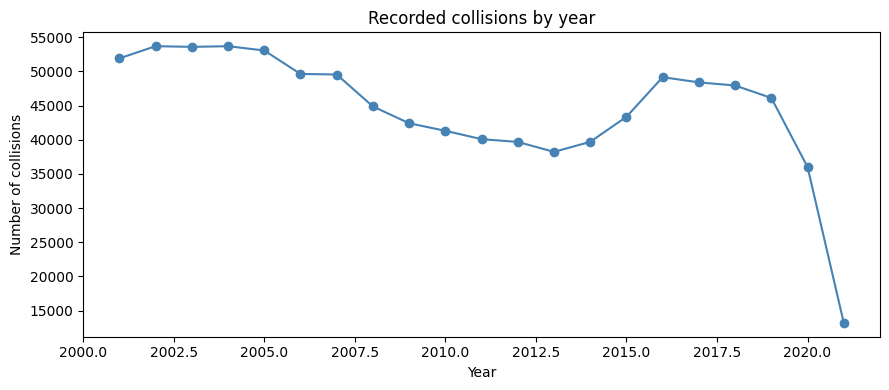

Yearly counts may reflect uneven source coverage, not only safety changes.


In [28]:
# Yearly Trend of Collisions
yearly_counts = (analysis_time.filter(F.col("collision_year").isNotNull())
                 .groupBy("collision_year").count()
                 .orderBy("collision_year").toPandas())
print(yearly_counts.to_string(index=False))
ax = yearly_counts.plot.line(x="collision_year", y="count", marker="o",
                             legend=False, figsize=(9, 4), color="steelblue")
ax.set(title="Recorded collisions by year", xlabel="Year",
       ylabel="Number of collisions")
plt.tight_layout()
plt.show()
print("Yearly counts may reflect uneven source coverage, not only safety changes.")

                 count month_name
collision_month                  
1                78323        Jan
2                75781        Feb
3                82167        Mar
4                76208        Apr
5                78961        May
6                74762        Jun
7                74776        Jul
8                76960        Aug
9                77019        Sep
10               83274        Oct
11               78061        Nov
12               79499        Dec


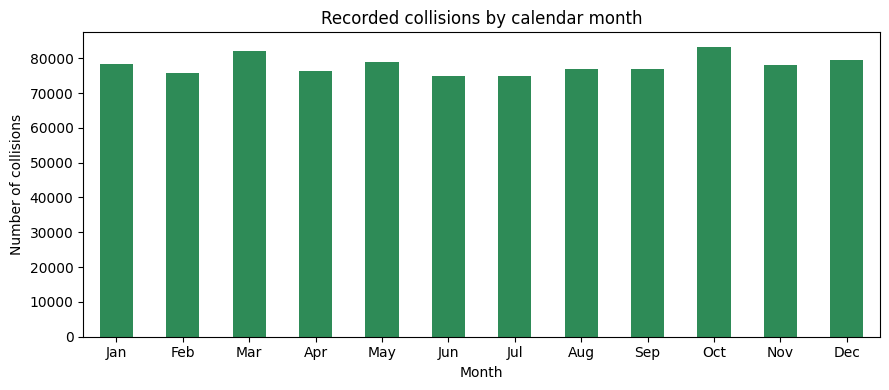

In [29]:
# Monthly Trend of Collisions
import calendar
monthly_counts = (analysis_time.filter(F.col("collision_month").isNotNull())
                  .groupBy("collision_month").count()
                  .orderBy("collision_month").toPandas()
                  .set_index("collision_month").reindex(range(1, 13)).fillna(0))
monthly_counts["count"] = monthly_counts["count"].astype(int)
monthly_counts["month_name"] = [calendar.month_abbr[i] for i in range(1, 13)]
print(monthly_counts.to_string())
ax = monthly_counts.plot.bar(x="month_name", y="count", legend=False,
                             figsize=(9, 4), color="seagreen")
ax.set(title="Recorded collisions by calendar month", xlabel="Month",
       ylabel="Number of collisions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

                count
collision_hour       
0               18360
1               17567
2               17599
3               11943
4               10650
5               15281
6               25149
7               47496
8               48939
9               38586
10              39045
11              44731
12              51959
13              53230
14              60158
15              70857
16              67432
17              73255
18              58855
19              41724
20              33766
21              31228
22              27312
23              22585


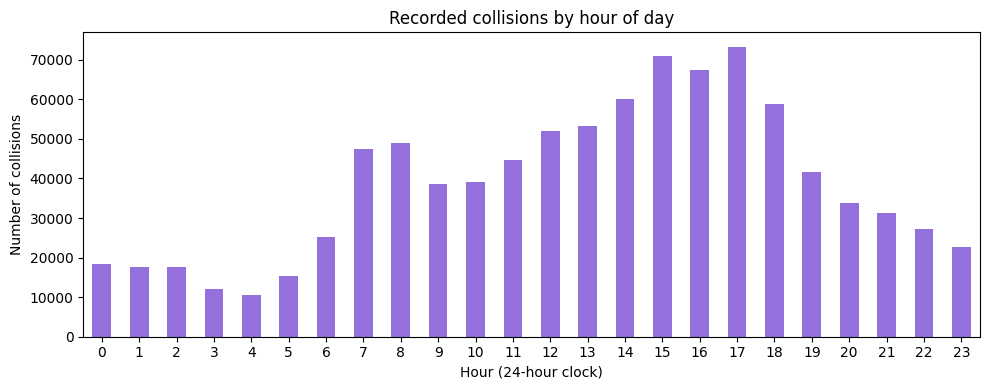

These are collision counts, not exposure-adjusted hourly risk.


In [30]:
# Hourly Trend of Collisions
hourly_counts = (analysis_time.filter(F.col("collision_hour").isNotNull())
                 .groupBy("collision_hour").count()
                 .orderBy("collision_hour").toPandas()
                 .set_index("collision_hour").reindex(range(24)).fillna(0))
hourly_counts["count"] = hourly_counts["count"].astype(int)
print(hourly_counts.to_string())
ax = hourly_counts.plot.bar(y="count", legend=False, figsize=(10, 4),
                            color="mediumpurple")
ax.set(title="Recorded collisions by hour of day",
       xlabel="Hour (24-hour clock)", ylabel="Number of collisions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print("These are collision counts, not exposure-adjusted hourly risk.")

#**4. ETL Querying** <font color = red>[35 marks]</font> <br>

## **4.1. Top 5 Counties** <font color = red>[4 marks]</font> <br>

Q: Identify the top 5 counties with the highest number of collisions.

In [31]:
# Query: top five counties by recorded collision count
analysis_time.createOrReplaceTempView("crashes")
top_counties_sql = spark.sql("""
    SELECT county, COUNT(*) AS collision_count
    FROM crashes
    WHERE county IS NOT NULL AND county <> 'Unknown'
    GROUP BY county
    ORDER BY collision_count DESC
    LIMIT 5
""")
top_counties_sql.show(truncate=False)

+--------------+---------------+
|county        |collision_count|
+--------------+---------------+
|los angeles   |284100         |
|orange        |72042          |
|san bernardino|56737          |
|san diego     |53105          |
|riverside     |48686          |
+--------------+---------------+



## **4.2. Month with Highest Collisions** <font color = red>[5 marks]</font> <br>

Q. Identify the month with the highest number of collisions.

In [32]:
# Query: calendar month with the most recorded collisions
highest_month_sql = spark.sql("""
    SELECT collision_month,
           date_format(make_date(2020, collision_month, 1), 'MMMM') AS month_name,
           COUNT(*) AS collision_count
    FROM crashes
    WHERE collision_month BETWEEN 1 AND 12
    GROUP BY collision_month
    ORDER BY collision_count DESC
    LIMIT 1
""")
highest_month_sql.show(truncate=False)

+---------------+----------+---------------+
|collision_month|month_name|collision_count|
+---------------+----------+---------------+
|10             |October   |83274          |
+---------------+----------+---------------+



## **4.3. Weather Conditions with Highest Collisions.** <font color = red>[5 marks]</font> <br>

Q. Determine the most common weather condition during collisions.

In [33]:
# Query: most common recorded weather condition
common_weather_sql = spark.sql("""
    SELECT weather_condition, COUNT(*) AS collision_count
    FROM crashes
    WHERE weather_condition IS NOT NULL
      AND weather_condition <> 'Unknown'
    GROUP BY weather_condition
    ORDER BY collision_count DESC
    LIMIT 1
""")
common_weather_sql.show(truncate=False)

+-----------------+---------------+
|weather_condition|collision_count|
+-----------------+---------------+
|clear            |769927         |
+-----------------+---------------+



## **4.4. Fatal Collisions.** <font color = red>[5 marks]</font> <br>

Q. Calculate the percentage of collisions that resulted in fatalities.

In [34]:
# Query: percentage of sampled collisions recorded as fatal
fatality_sql = spark.sql("""
    SELECT COUNT(*) AS collision_rows,
           SUM(CASE WHEN killed_victims > 0
                     OR lower(collision_severity) LIKE '%fatal%'
                    THEN 1 ELSE 0 END) AS recorded_fatal_rows,
           SUM(CASE WHEN killed_victims IS NULL THEN 1 ELSE 0 END)
               AS missing_killed_count,
           ROUND(100.0 * SUM(CASE WHEN killed_victims > 0
                                   OR lower(collision_severity) LIKE '%fatal%'
                                  THEN 1 ELSE 0 END) / COUNT(*), 4)
               AS recorded_fatal_pct
    FROM crashes
""")
fatality_sql.show(truncate=False)
print("Interpret as a percentage of this collision sample only.")

+--------------+-------------------+--------------------+------------------+
|collision_rows|recorded_fatal_rows|missing_killed_count|recorded_fatal_pct|
+--------------+-------------------+--------------------+------------------+
|935791        |0                  |200                 |0.0000            |
+--------------+-------------------+--------------------+------------------+

Interpret as a percentage of this collision sample only.


## **4.5. Dangerous Time for Collisions.** <font color = red>[5 marks]</font> <br>

Q. Find the most dangerous time of day for collisions.

In [35]:
# Query: hour with the most recorded collisions
peak_hour_sql = spark.sql("""
    SELECT collision_hour, COUNT(*) AS collision_count
    FROM crashes
    WHERE collision_hour BETWEEN 0 AND 23
    GROUP BY collision_hour
    ORDER BY collision_count DESC
    LIMIT 1
""")
peak_hour_sql.show(truncate=False)
print("Most frequent recorded hour; hourly traffic exposure is unavailable.")

+--------------+---------------+
|collision_hour|collision_count|
+--------------+---------------+
|17            |73255          |
+--------------+---------------+

Most frequent recorded hour; hourly traffic exposure is unavailable.


## **4.6. Road Surface Conditions.** <font color = red>[5 marks]</font> <br>

Q. Identify the top 5 road surface conditions with the highest collision frequency.

In [36]:
# Query: top five road-surface conditions by collision frequency
road_surface_sql = spark.sql("""
    SELECT road_surface, COUNT(*) AS collision_count
    FROM crashes
    WHERE road_surface IS NOT NULL AND road_surface <> 'Unknown'
    GROUP BY road_surface
    ORDER BY collision_count DESC
    LIMIT 5
""")
road_surface_sql.show(truncate=False)

+------------+---------------+
|road_surface|collision_count|
+------------+---------------+
|dry         |845637         |
|wet         |76833          |
|snowy       |4122           |
|slippery    |1048           |
|H           |10             |
+------------+---------------+



## **4.7. Lighting Conditions.** <font color = red>[5 marks]</font> <br>

Q. Analyze lighting conditions that contribute to the highest number of collisions.

In [37]:
# Query: top three lighting conditions by recorded collisions
lighting_sql = spark.sql("""
    SELECT lighting, COUNT(*) AS collision_count
    FROM crashes
    WHERE lighting IS NOT NULL AND lighting <> 'Unknown'
    GROUP BY lighting
    ORDER BY collision_count DESC
    LIMIT 3
""")
lighting_sql.show(truncate=False)
print("Collision frequency is not evidence that a lighting condition causes crashes.")

+--------------------------+---------------+
|lighting                  |collision_count|
+--------------------------+---------------+
|daylight                  |625574         |
|dark with street lights   |195867         |
|dark with no street lights|74634          |
+--------------------------+---------------+

Collision frequency is not evidence that a lighting condition causes crashes.


#5. Conclusion <font color = red>[10 marks]</font> <br>

Write your conclusion.

In [38]:
# Evidence summary to support your own British-English conclusion
print("Collision severity (count and percentage):")
print(severity_counts.to_string(index=False))
print("\nWeather (count and percentage):")
print(weather_counts.to_string(index=False))
print("\nVictim ages: valid", known_age, "missing or invalid", missing_age)
print("\nTop counties (sample counts):")
print(county_counts.head(10).to_string(index=False))
print("\nWeekday counts:")
print(weekday_counts.to_string())
print("\nVictims per collision by severity:")
print(severity_victims.to_string(index=False))
print("\nSevere-injury percentage by weather:")
print(weather_severity_pct.get("severe injury", pd.Series(dtype=float)).round(2).to_string())
print("\nSevere-injury percentage by lighting:")
print(lighting_severity_pct.get("severe injury", pd.Series(dtype=float)).round(2).to_string())
print("\nYearly counts:")
print(yearly_counts.to_string(index=False))
print("\nMonthly counts:")
print(monthly_counts.to_string())
print("\nHourly counts:")
print(hourly_counts.to_string())
print("\nRecorded fatality query:")
fatality_sql.show(truncate=False)
print("Caveats: independent table samples; many missing coordinates; 27 repeated case IDs; counts are not exposure-adjusted risk.")

Collision severity (count and percentage):
  collision_severity  count  percentage
property damage only 570480       60.96
                pain 226492       24.20
        other injury 116681       12.47
       severe injury  22138        2.37

Weather (count and percentage):
weather_condition  count  percentage
            clear 769927       82.28
           cloudy 122155       13.05
          raining  32341        3.46
          Unknown   4626        0.49
              fog   3901        0.42
          snowing   1370        0.15
            other   1081        0.12
             wind    390        0.04

Victim ages: valid 931758 missing or invalid 32175

Top counties (sample counts):
        county  count  percentage
   los angeles 284100       30.36
        orange  72042        7.70
san bernardino  56737        6.06
     san diego  53105        5.67
     riverside  48686        5.20
       alameda  46525        4.97
    sacramento  40503        4.33
   santa clara  34116        3.65
  

### Conclusion

The analysis of 935,791 sampled California collision records shows that 60.96% were classified as property damage only and 2.37% as severe injury. Los Angeles had the largest recorded county count (284,100, or 30.36% of records with a county). Friday had the highest weekday count (154,544), October the highest monthly count (83,274), and 17:00 the highest hourly count (73,255). These are counts of recorded collisions, not measures of individual risk: traffic volume and distance travelled were unavailable.

Clear weather was recorded for 82.28% of collisions. This does not establish that clear weather increases collision risk, because the amount of driving in each condition is unknown. Among recorded collisions, the severe injury share was 4.35% in darkness without street lights, compared with 1.92% in daylight. This association supports closer examination of lighting, speed and road design; it does not establish a causal effect of lighting on its own.

Road safety teams could prioritise detailed audits of high count locations and busy periods, then assess junction design, speed management and signal timing. Locations with frequent severe collisions in darkness merit a lighting review. Pedestrian and cyclist collision indicators should be analysed separately before selecting crossing or cycle route improvements. Each proposed intervention should be evaluated against a baseline using injury outcomes and, where possible, traffic exposure.

The findings have important limits. About 71.5% of collision records lack coordinates, 27 case IDs repeat, and the collision, party and victim files are separate samples. The collision sample has no recorded fatal rows and 200 missing killed victim counts, so it cannot support a statewide fatality estimate. Future work should validate identifiers and locations, add exposure data, and test hotspot prediction on later years and held out locations. The S3 storage step should be reported as complete only after the processed data are uploaded and checked in the bucket.

#6. Visualization Integration using Tableau/ PowerBI <font color = red>[Optional]</font> <br>